In [ ]:
import json
import os
import sys
from pathlib import Path

if "google.colab" in sys.modules and not Path("src").exists():
    print("Запуск у Google Colab — переконайтесь, що папка 'src/' завантажена у робочу директорію.")

import src 
import keras
import numpy as np
import pandas as pd
import tensorflow as tf

from src.config import SEED, ensure_directories, set_global_seed

ensure_directories()
set_global_seed(SEED)
accel_info = f"TF devices: {tf.config.list_physical_devices()}"
if keras.backend.backend() == "torch":
    import torch
    mps_ok = torch.backends.mps.is_available()
    accel_info = f"Apple Metal GPU (MPS): {'ACTIVE' if mps_ok else 'CPU'} (torch {torch.__version__})"
print(f"Keras: {keras.__version__} (backend={keras.backend.backend()}) | TensorFlow: {tf.__version__}")
print(f"Апаратне прискорення: {accel_info}")


Keras: 3.15.1 (backend=torch) | TensorFlow: 2.21.0
Апаратне прискорення: Apple Metal GPU (MPS): ACTIVE (torch 2.15.0)


[trainer] Loaded Stage-1 bottleneck features for 'resnet50' (dim=2048, train=19997).
[trainer] Caching frozen prefix 'resnet50:conv4_block6_out' shape=(1024, 14, 14) (2000 tr / 500 val / 2502 test, temp disk=1.87 GB) ...
[trainer] resnet50_tune_blocks_1 | Best FT Ep 1/8 | Val Loss: 0.0526 | Test Acc: 98.48% (38 errs) | Time: 151.4s
[trainer] Caching frozen prefix 'resnet50:conv3_block4_out' shape=(512, 28, 28) (2000 tr / 500 val / 2502 test, temp disk=3.74 GB) ...
[trainer] resnet50_tune_blocks_2 | Best FT Ep 1/8 | Val Loss: 0.0487 | Test Acc: 98.64% (34 errs) | Time: 629.7s


Prefix [resnet50:test]: 100%|##########| 79/79 [01:02<00:00,  1.26it/s]


,Config,Unfreeze Scope,Trainable Params,Best Val Loss,Overfit Gap (%),Test Accuracy (%),Test Loss,ROC-AUC
0,1 блок(и),1 етап: conv5_block1..conv5_block3 (BatchNorm ...,15478273,0.05258,1.2,98.48,0.0454,0.999
1,2 блок(и),2 етапи: conv4_block1..6 + conv5_block1..3 (Ba...,22566401,0.04872,1.2,98.64,0.0436,0.999


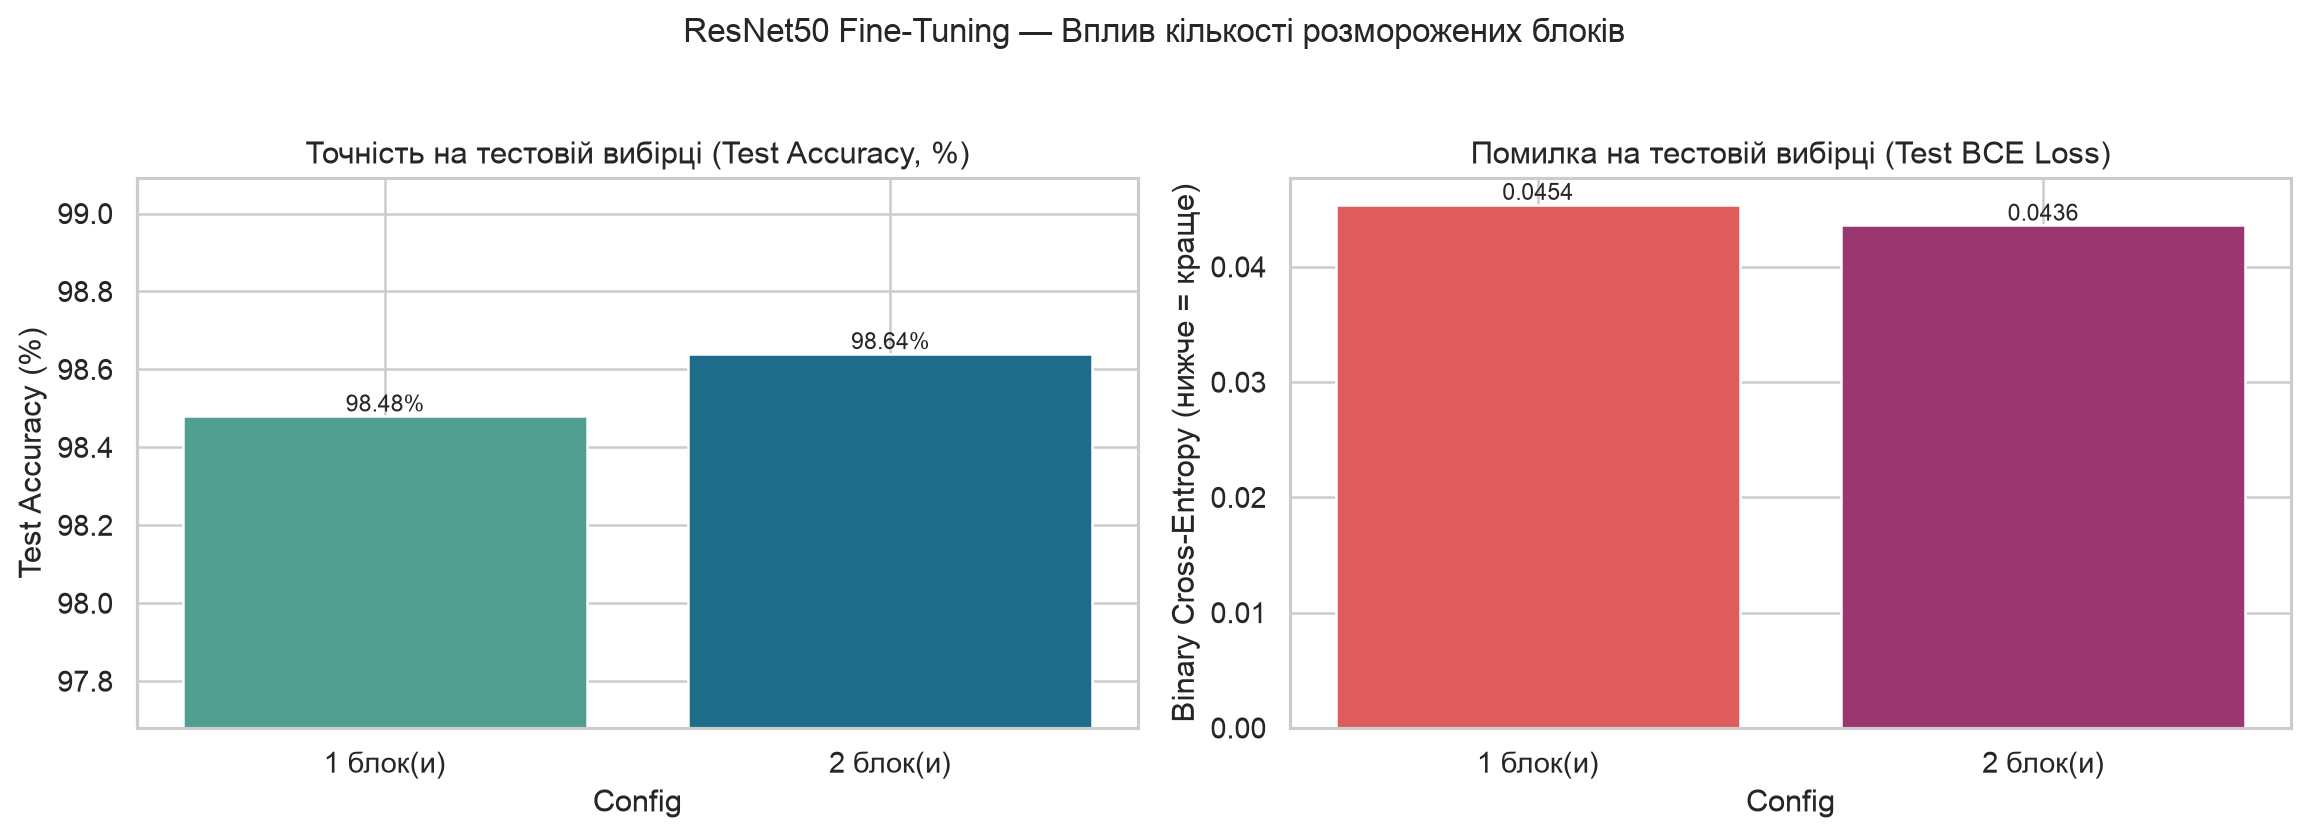

In [ ]:
from src.config import MODELS_DIR, RESULTS_DIR, cleanup_temp_prefix_cache
from src.trainer import (
    extract_or_load_bottleneck_features,
    finalize_and_save_finetuned_model,
    predict_external_images,
    prepare_prefix_cache,
    run_finetuning_experiment,
)
from src.visualization import (
    plot_confusion_matrix,
    plot_external_predictions_grid,
    plot_hyperparameter_bars,
    plot_multi_curves_comparison,
    plot_two_stage_curves,
)

bottleneck_data, _ = extract_or_load_bottleneck_features("resnet50")

block_rows = []
block_records = []
for n_blk in (1, 2):
    pc_sub = prepare_prefix_cache("resnet50", unfreeze_blocks=n_blk, train_samples=2000, val_samples=500)
    _, rec = run_finetuning_experiment(
        model_key="resnet50",
        bottleneck_features=bottleneck_data,
        prefix_cache=pc_sub,
        unfreeze_blocks=n_blk,
        dense_units=256,
        dropout_rate=0.5,
        optimizer_name="adam",
        learning_rate=1e-5,
        batch_size=50,
        warmup_epochs=10,
        finetune_epochs=8,
        experiment_name=f"resnet50_tune_blocks_{n_blk}",
    )
    block_records.append(rec)
    tm = rec["test_metrics"]
    block_rows.append({
        "Config": f"{n_blk} блок(и)",
        "Unfreeze Scope": rec["unfreeze_description"],
        "Trainable Params": rec["trainable_params"],
        "Best Val Loss": rec["best_val_loss"],
        "Overfit Gap (%)": round(rec["overfitting_acc_gap"] * 100, 2),
        "Test Accuracy (%)": round(tm["accuracy"] * 100, 2),
        "Test Loss": round(tm["loss"], 4),
        "ROC-AUC": round(tm["roc_auc"], 5),
    })

df_blocks = pd.DataFrame(block_rows)
display(df_blocks)
plot_hyperparameter_bars(
    df_blocks,
    x_col="Config",
    title="ResNet50 Fine-Tuning — Вплив кількості розморожених блоків",
    save_name="02_resnet50_blocks_comparison.png",
)


[trainer] Caching frozen prefix 'resnet50:conv4_block6_out' shape=(1024, 14, 14) (2000 tr / 500 val / 2502 test, temp disk=1.87 GB) ...
[trainer] resnet50_tune_adam_lr_1e-4 | Best FT Ep 1/8 | Val Loss: 0.0504 | Test Acc: 98.12% (47 errs) | Time: 144.9s
[trainer] resnet50_tune_adam_lr_1e-5 | Best FT Ep 1/8 | Val Loss: 0.0526 | Test Acc: 98.48% (38 errs) | Time: 152.7s
[trainer] resnet50_tune_adam_lr_1e-6 | Best FT Ep 1/8 | Val Loss: 0.0465 | Test Acc: 98.56% (36 errs) | Time: 152.7s
[trainer] resnet50_tune_rmsprop_lr_1e-5 | Best FT Ep 1/8 | Val Loss: 0.0523 | Test Acc: 98.72% (32 errs) | Time: 132.3s


Prefix [resnet50:test]: 100%|##########| 79/79 [01:13<00:00,  1.08it/s]


,Setting,Optimizer,Learning Rate,Best Epoch,Best Val Loss,Overfit Gap (%),Test Accuracy (%),Test Loss,ROC-AUC
0,Adam lr=1e-4,ADAM,0.000100,1,0.05039,1.4,98.12,0.0466,0.99874
1,Adam lr=1e-5,ADAM,0.000010,1,0.05258,1.2,98.48,0.0454,0.99900
2,Adam lr=1e-6,ADAM,0.000001,1,0.04649,1.4,98.56,0.0410,0.99866
3,RMSprop lr=1e-5,RMSPROP,0.000010,1,0.05231,1.4,98.72,0.0416,0.99884


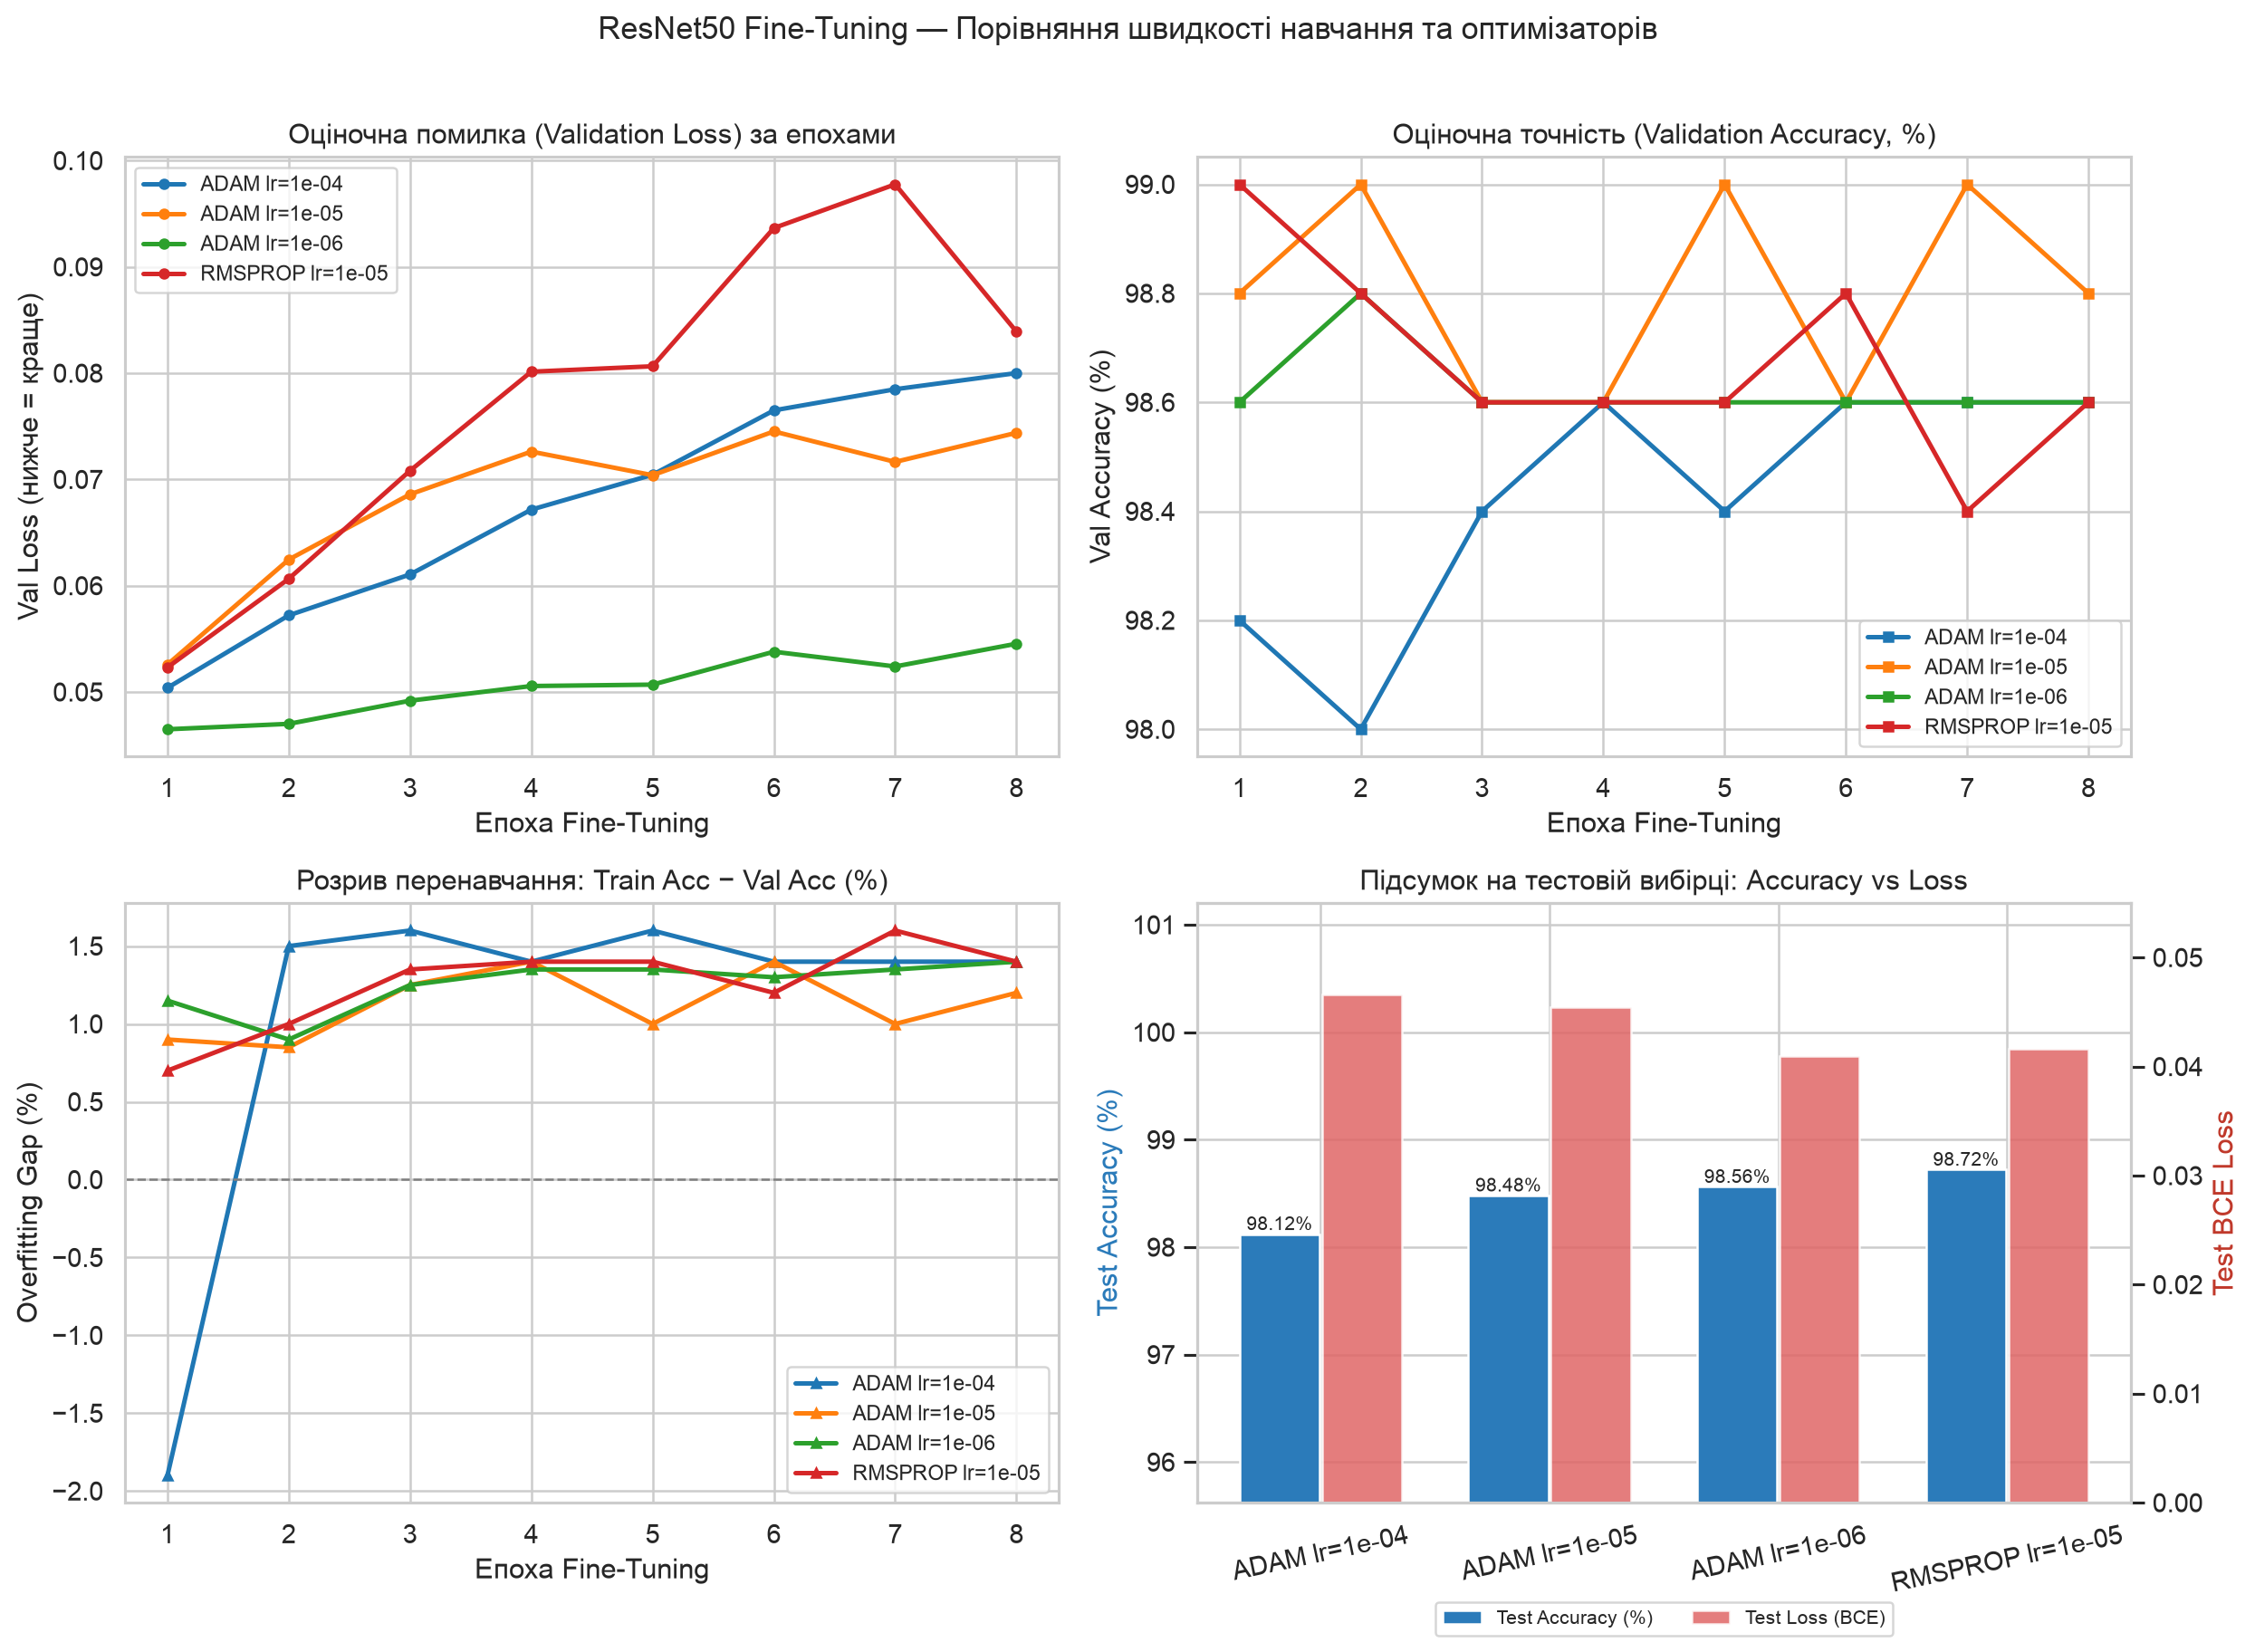

In [3]:
pc_tune = prepare_prefix_cache("resnet50", unfreeze_blocks=1, train_samples=2000, val_samples=500)
lr_opt_configs = [
    ("Adam lr=1e-4", "adam", 1e-4),
    ("Adam lr=1e-5", "adam", 1e-5),
    ("Adam lr=1e-6", "adam", 1e-6),
    ("RMSprop lr=1e-5", "rmsprop", 1e-5),
]

lr_records = []
lr_rows = []
for label, opt_name, lr_val in lr_opt_configs:
    tag_clean = label.lower().replace(" ", "_").replace("=", "_")
    _, rec = run_finetuning_experiment(
        model_key="resnet50",
        bottleneck_features=bottleneck_data,
        prefix_cache=pc_tune,
        unfreeze_blocks=1,
        dense_units=256,
        dropout_rate=0.5,
        optimizer_name=opt_name,
        learning_rate=lr_val,
        batch_size=50,
        warmup_epochs=10,
        finetune_epochs=8,
        experiment_name=f"resnet50_tune_{tag_clean}",
    )
    lr_records.append(rec)
    tm = rec["test_metrics"]
    lr_rows.append({
        "Setting": label,
        "Optimizer": opt_name.upper(),
        "Learning Rate": lr_val,
        "Best Epoch": rec["best_epoch"],
        "Best Val Loss": rec["best_val_loss"],
        "Overfit Gap (%)": round(rec["overfitting_acc_gap"] * 100, 2),
        "Test Accuracy (%)": round(tm["accuracy"] * 100, 2),
        "Test Loss": round(tm["loss"], 4),
        "ROC-AUC": round(tm["roc_auc"], 5),
    })

cleanup_temp_prefix_cache()
df_lr = pd.DataFrame(lr_rows)
display(df_lr)
df_lr.to_csv(RESULTS_DIR / "resnet50_hyperparameter_studies.csv", index=False)

plot_multi_curves_comparison(
    lr_records,
    label_fn=lambda r: f"{r['optimizer'].upper()} {r['learning_rate']:.0e}",
    suptitle="ResNet50 Fine-Tuning — Підбір швидкості навчання та оптимізатора",
    save_name="02_resnet50_lr_opt_comparison.png",
)


Оптимальний режим донавчання ResNet50 за мінімумом Val Loss: optimizer=adam, lr=1e-06, blocks=1
[trainer] Caching frozen prefix 'resnet50:conv4_block6_out' shape=(1024, 14, 14) (6000 tr / 2498 val / 2502 test, temp disk=4.11 GB) ...
[trainer] resnet50_champion_finetuned | Best FT Ep 0/8 | Val Loss: 0.0256 | Test Acc: 99.20% (20 errs) | Time: 586.2s
Found 19997 files belonging to 2 classes.
Found 2498 files belonging to 2 classes.
Found 2502 files belonging to 2 classes.
[trainer] Verified End-to-End ResNet50 on raw test JPEGs (max prob diff vs FP16 prefix split = 0.00007).
[trainer] Saved resnet50_finetuned.keras (92.62 MB) | Test Acc: 99.20% (20 errs / 2502) | Loss: 0.0230 | ROC-AUC: 0.99936


Prefix [resnet50:test]: 100%|##########| 79/79 [01:42<00:00,  1.29s/it]


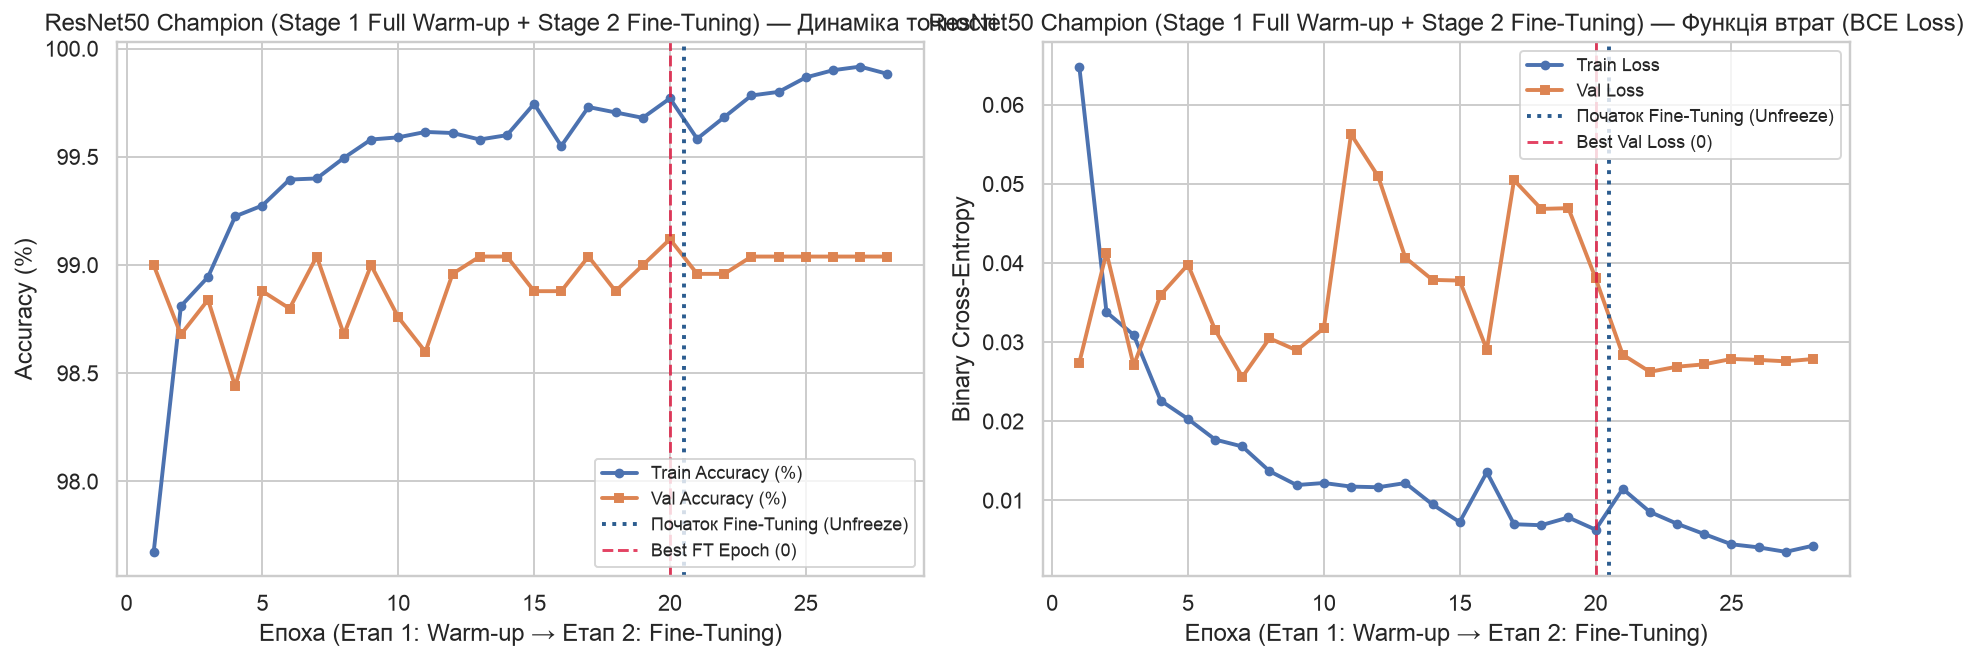

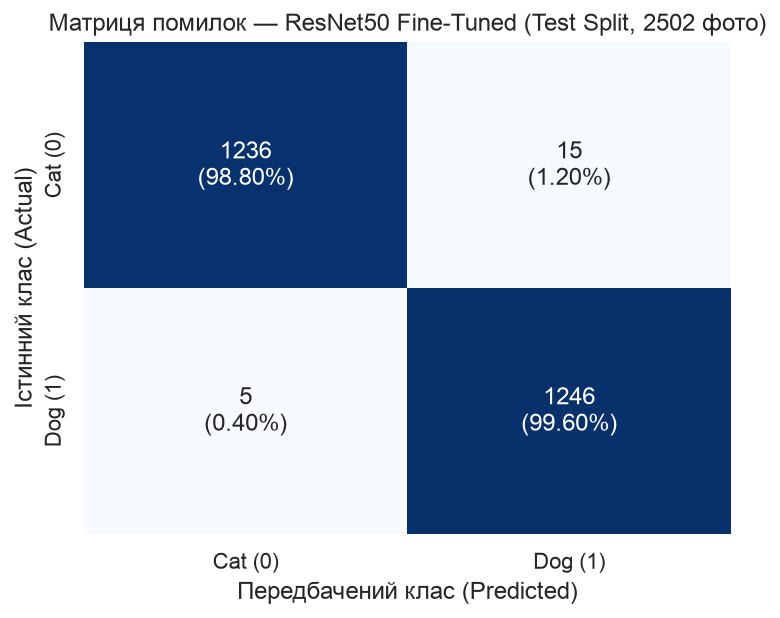

,filename,rel_path,true_class,pred_class,dog_probability,confidence,bce_loss,correct
0,ext_cat_01_tabby.jpg,cats/ext_cat_01_tabby.jpg,cats,cats,0.00000,1.00000,0.00000,True
1,ext_cat_02_orange.jpg,cats/ext_cat_02_orange.jpg,cats,cats,0.00000,1.00000,0.00000,True
2,ext_cat_03_white_cat.jpg,cats/ext_cat_03_white_cat.jpg,cats,cats,0.00000,1.00000,0.00000,True
3,ext_cat_04_kitten.jpg,cats/ext_cat_04_kitten.jpg,cats,cats,0.00004,0.99996,0.00004,True
4,ext_cat_05_portrait.jpg,cats/ext_cat_05_portrait.jpg,cats,cats,0.00000,1.00000,0.00000,True
5,ext_dog_01_golden_retriever.jpg,dogs/ext_dog_01_golden_retriever.jpg,dogs,dogs,1.00000,1.00000,0.00000,True
6,ext_dog_02_samoyed.jpg,dogs/ext_dog_02_samoyed.jpg,dogs,dogs,0.92738,0.92738,0.07539,True
7,ext_dog_03_beagle.jpg,dogs/ext_dog_03_beagle.jpg,dogs,dogs,1.00000,1.00000,0.00000,True
8,ext_dog_04_german_shepherd.jpg,dogs/ext_dog_04_german_shepherd.jpg,dogs,dogs,1.00000,1.00000,0.00000,True
9,ext_dog_05_pug.jpg,dogs/ext_dog_05_pug.jpg,dogs,dogs,0.99863,0.99863,0.00137,True


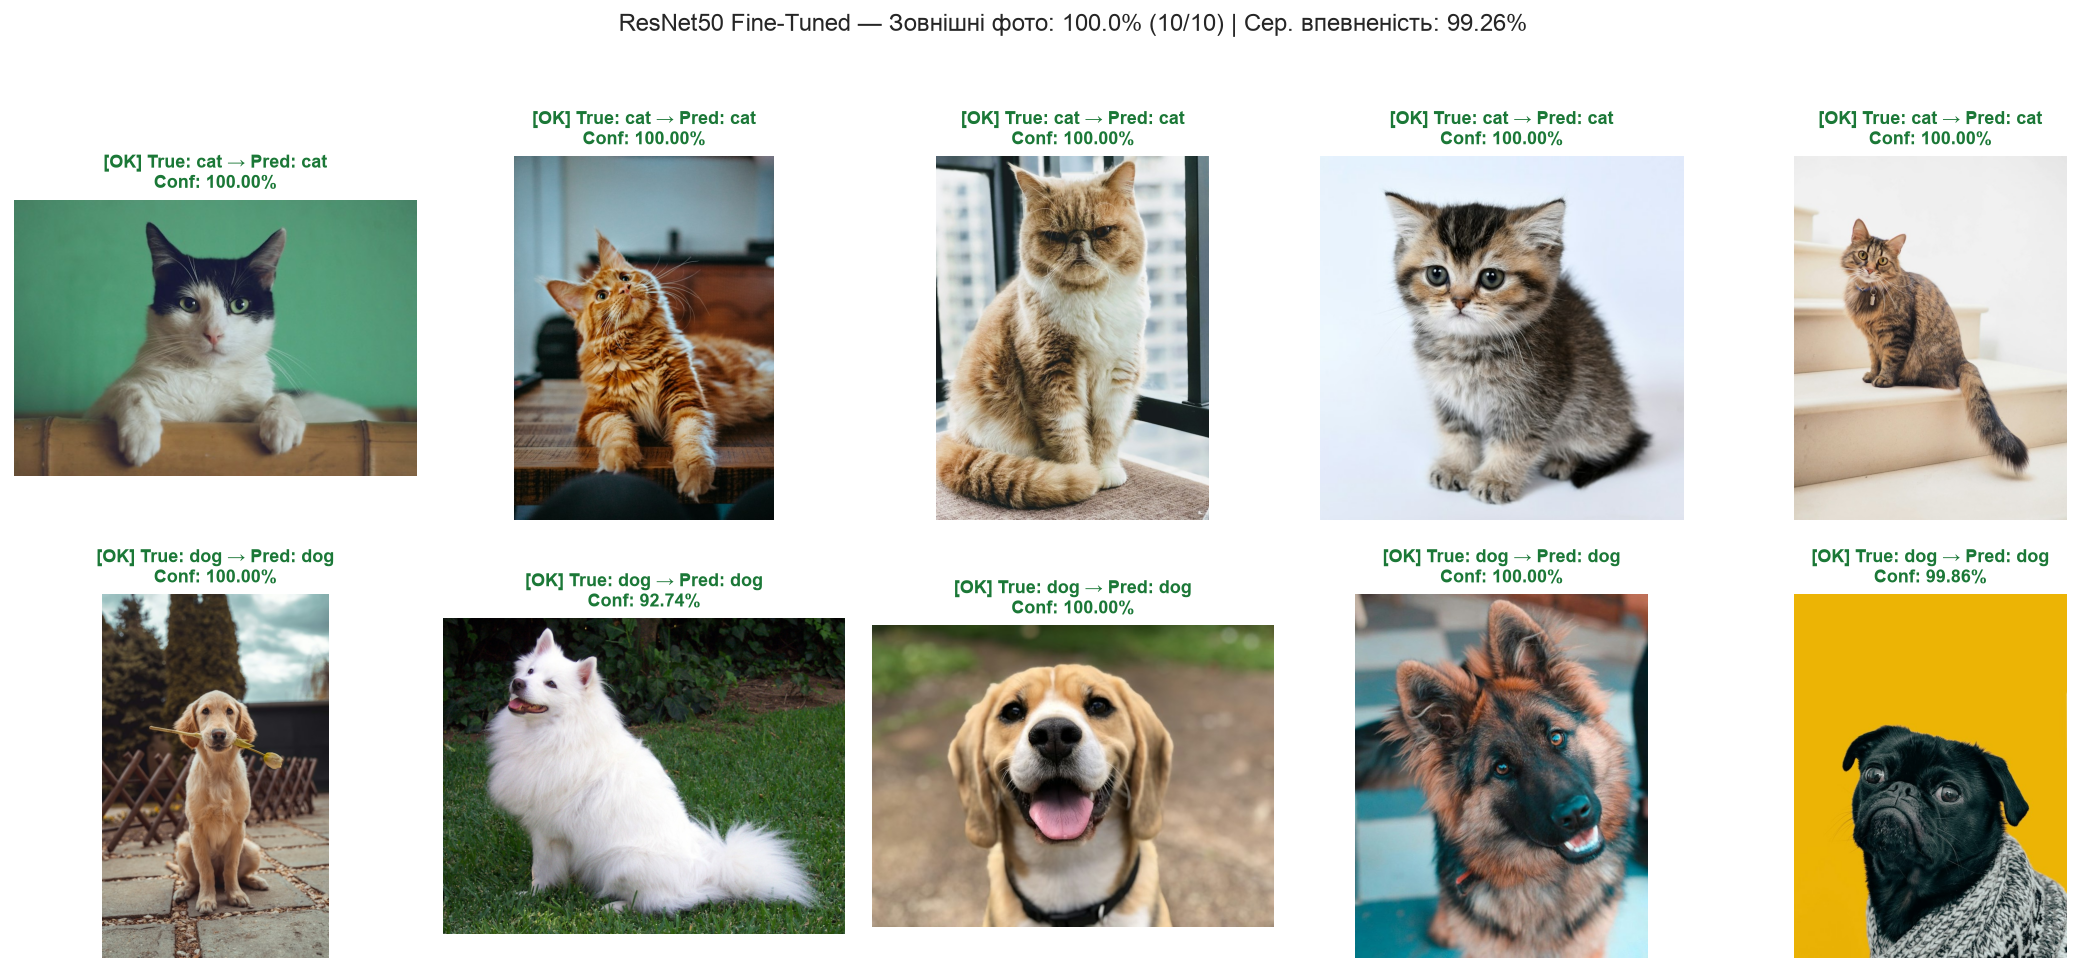

In [4]:
safe_lr_df = df_lr[df_lr["Learning Rate"] <= 1e-5]
best_row = safe_lr_df.sort_values("Best Val Loss").iloc[0]
best_opt = str(best_row["Optimizer"]).lower()
best_lr = float(best_row["Learning Rate"])
print(f"Оптимальний режим донавчання ResNet50 за мінімумом Val Loss: optimizer={best_opt}, lr={best_lr:.0e}, blocks=1")

full_prefix = prepare_prefix_cache(
    "resnet50",
    unfreeze_blocks=1,
    train_samples=6000,
    val_samples=None,
)

champ_suffix, champ_rec = run_finetuning_experiment(
    model_key="resnet50",
    bottleneck_features=bottleneck_data,
    prefix_cache=full_prefix,
    unfreeze_blocks=1,
    dense_units=256,
    dropout_rate=0.5,
    optimizer_name=best_opt,
    learning_rate=best_lr,
    batch_size=50,
    warmup_epochs=20,
    finetune_epochs=8,
    warmup_on_full_train=True,
    experiment_name="resnet50_champion_finetuned",
    keep_model_in_memory=True,
)

plot_two_stage_curves(
    champ_rec,
    title_prefix="ResNet50 Champion (Stage 1 Full Warm-up + Stage 2 Fine-Tuning)",
    save_name="02_resnet50_champion_curves.png",
)

final_summary = finalize_and_save_finetuned_model(
    model_key="resnet50",
    trained_suffix_model=champ_suffix,
    experiment_record=champ_rec,
    prefix_cache=full_prefix,
)

plot_confusion_matrix(
    final_summary["test_metrics"]["confusion_matrix"],
    model_title="ResNet50 Fine-Tuned (Test Split, 2502 фото)",
    save_name="02_resnet50_confusion_matrix.png",
)

df_ext = predict_external_images(MODELS_DIR / final_summary["save_filename"])
display(df_ext)
plot_external_predictions_grid(
    df_ext,
    model_title="ResNet50 Fine-Tuned",
    save_name="02_resnet50_external_test.png",
)
